# Master Validation: Bandwidth-Aware KV Offloading (`R_cap` + Paged Oracle)

Validates the 5-step experimental workflow on **Exgentic SWE-bench** (`Qwen/Qwen3.6-35B-A3B-FP8`, `n=40`, `seed=42`):
1. **Exp 1:** GPU Hardware Characterization & Active-KV Byte/Token Sweet Spot ($R_{\text{bw}}^*$, FIFO)
2. **Exp 2:** 6-Policy Shootout (`Recompute`, `Pack Full LRU`, `Pack FC Oracle`, `Pack Paged LRU`, `Pack Paged Oracle`, `BW-Aware Oracle`)
3. **Exp 3:** Mechanism Verification (`Active` vs `St.TOOL` Residency, `St.DECODE`, and `p99+` TTFT Decomposition)
4. **Exp 4:** Tight-HBM Ablation (`32, 40, 48, 64 GB`) isolating `R_bw*` vs. `Paged Oracle`
5. **Exp 5:** Cross-GPU Generalization (`H100 PCIe`, `H100 SXM`, `H100 NVL`, `H200 SXM`)

=== Experiment 1: R_cap (FIFO) Sweep at 48 GB & 64 GB (lambda=0.15) ===
HBM  | R_cap (tok / GB)   | MeanE2E   | Decode/r | EvictGB  | TTFTp95  | LastDone 
----------------------------------------------------------------------------------
 48G | 250K (30.5G)       |  1742.7 s |  655.8 s |  726.1 G |  28.11 s |  3963.9 s
 48G | 300K (36.6G)       |  1705.1 s |  744.3 s | 1460.5 G |  31.41 s |  3922.4 s
 48G | 350K (42.7G)       |  1702.3 s |  831.3 s | 2191.8 G |  32.39 s |  3782.7 s
 48G | 400K (48.8G)       |  1733.8 s |  908.4 s | 3108.1 G |  33.68 s |  3735.3 s
 48G | 450K (54.9G)       |  1728.7 s |  909.2 s | 3208.8 G |  29.97 s |  3735.9 s
 48G | 500K (61.0G)       |  1728.7 s |  909.2 s | 3208.8 G |  29.97 s |  3735.9 s
 48G | Uncapped           |  1728.7 s |  909.2 s | 3208.8 G |  29.97 s |  3735.9 s
----------------------------------------------------------------------------------
 64G | 250K (30.5G)       |  1742.0 s |  654.2 s |  177.9 G |  41.45 s |  3943.5 s
 64G | 300K (36

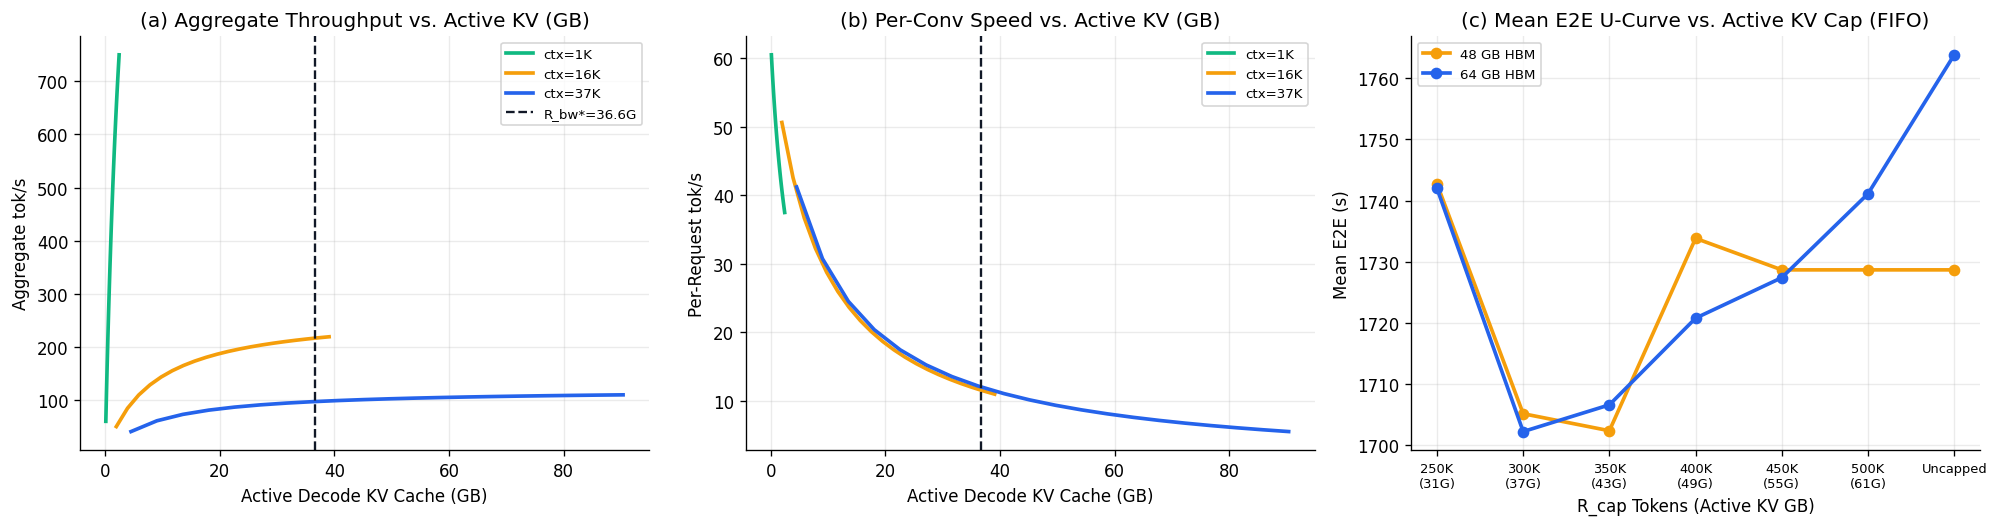

In [1]:
# Experiment 1: Hardware Characterization & Active-KV Token/Byte Sweet Spot (R_cap, FIFO)
import json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.scheduler_sim import CostModel, KVGeometry
from sim.paged_vs_oracle import run_capped_sim

plt.rcParams.update({
    "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

geom = KVGeometry(layers=32)
gb_per_tok = geom.bytes_per_token / (1024 ** 3)
cost = CostModel.from_calibration("results/sim_costmodel_h100_0905b.json")
raw_cm = json.load(open("results/sim_costmodel_h100_0905b.json"))

trace_path = "data/external_traces/exgentic_swebench.jsonl"
n_req, seed, max_time = 40, 42, 8000.0
r_caps = [250_000, 300_000, 350_000, 400_000, 450_000, 500_000, None]

exp1_tasks = []
for hbm in [48.0, 64.0]:
    for r in r_caps:
        lbl = f"{hbm:.0f}G|{r}"
        kw = {} if r is None else {"r_cap": r, "sjf": False}
        exp1_tasks.append((lbl, "CappedPagedOracle", hbm, 0.15, n_req, seed, max_time, trace_path, kw))

exp1_res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, exp1_tasks):
        exp1_res[k] = s

print("=== Experiment 1: R_cap (FIFO) Sweep at 48 GB & 64 GB (lambda=0.15) ===")
print(f"{'HBM':4s} | {'R_cap (tok / GB)':18s} | {'MeanE2E':9s} | {'Decode/r':8s} | {'EvictGB':8s} | {'TTFTp95':8s} | {'LastDone':9s}")
print("-" * 82)
for hbm in [48.0, 64.0]:
    for r in r_caps:
        s = exp1_res[f"{hbm:.0f}G|{r}"]
        rlbl = "Uncapped" if r is None else f"{r//1000}K ({r*gb_per_tok:4.1f}G)"
        dec = s["state_seconds"]["DECODE"] / s["total_requests"]
        print(f"{hbm:3.0f}G | {rlbl:18s} | {s['mean_e2e_s']:7.1f} s | {dec:6.1f} s | {s['total_evicted_gb']:6.1f} G | {s['ttft_p95']:6.2f} s | {s['makespan_done_s']:7.1f} s")
    print("-" * 82)

best_r = min([r for r in r_caps if r is not None], key=lambda r: exp1_res[f"64G|{r}"]["mean_e2e_s"])
print(f"Selected R_bw* = {best_r//1000}K tokens ({best_r*gb_per_tok:.1f} GB active KV)")

fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.5))
batches = np.arange(1, 21)
for ctx, col, lbl in [(1000, "#10b981", "ctx=1K"), (16000, "#f59e0b", "ctx=16K"), (37000, "#2563eb", "ctx=37K")]:
    kv_gb = batches * ctx * gb_per_tok
    dts = np.array([cost.step_time(int(b), int(b) * ctx, 0) for b in batches])
    axes[0].plot(kv_gb, batches / dts, label=lbl, color=col, lw=2.2)
    axes[1].plot(kv_gb, 1.0 / dts, label=lbl, color=col, lw=2.2)
axes[0].axvline(best_r * gb_per_tok, color="#111827", ls="--", lw=1.4, label=f"R_bw*={best_r*gb_per_tok:.1f}G")
axes[1].axvline(best_r * gb_per_tok, color="#111827", ls="--", lw=1.4)
axes[0].set_title("(a) Aggregate Throughput vs. Active KV (GB)")
axes[0].set_xlabel("Active Decode KV Cache (GB)"); axes[0].set_ylabel("Aggregate tok/s"); axes[0].legend(fontsize=8)
axes[1].set_title("(b) Per-Conv Speed vs. Active KV (GB)")
axes[1].set_xlabel("Active Decode KV Cache (GB)"); axes[1].set_ylabel("Per-Request tok/s"); axes[1].legend(fontsize=8)

xr = np.arange(len(r_caps))
xl = ["250K\n(31G)", "300K\n(37G)", "350K\n(43G)", "400K\n(49G)", "450K\n(55G)", "500K\n(61G)", "Uncapped"]
for hbm, col in [(48.0, "#f59e0b"), (64.0, "#2563eb")]:
    vals = [exp1_res[f"{hbm:.0f}G|{r}"]["mean_e2e_s"] for r in r_caps]
    axes[2].plot(xr, vals, marker="o", lw=2.2, color=col, label=f"{hbm:.0f} GB HBM")
axes[2].set_title("(c) Mean E2E U-Curve vs. Active KV Cap (FIFO)")
axes[2].set_xlabel("R_cap Tokens (Active KV GB)"); axes[2].set_ylabel("Mean E2E (s)")
axes[2].set_xticks(xr); axes[2].set_xticklabels(xl, fontsize=7.8); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

=== Experiment 2: 6-Policy Shootout ===
Rate | HBM  | Policy                     | MeanE2E   | Decode/r | TTFTp95  | EvictGB  | LastDone 
------------------------------------------------------------------------------------------------
0.15 |  48G | 1. Recompute (vLLM)        |  2645.4 s | 1440.7 s |   0.00 s |    0.0 G |  5291.0 s
0.15 |  48G | 2. Pack (Full LRU)         |  1734.1 s |  916.3 s |  35.23 s | 3642.7 G |  3720.5 s
0.15 |  48G | 3. Pack (FC Oracle)        |  1727.8 s |  910.1 s |  27.88 s | 3698.1 G |  3757.1 s
0.15 |  48G | 4. Pack (Paged LRU)        |  1732.3 s |  914.1 s |  30.31 s | 3506.6 G |  3714.0 s
0.15 |  48G | 5. Pack (Paged Oracle)     |  1728.7 s |  909.2 s |  29.97 s | 3208.8 G |  3735.9 s
0.15 |  48G | 6. BW-Aware (300K+Oracle)  |  1705.1 s |  744.3 s |  31.41 s | 1460.5 G |  3922.4 s
------------------------------------------------------------------------------------------------
0.15 |  64G | 1. Recompute (vLLM)        |  2752.0 s | 1821.4 s |   0.00 s |    

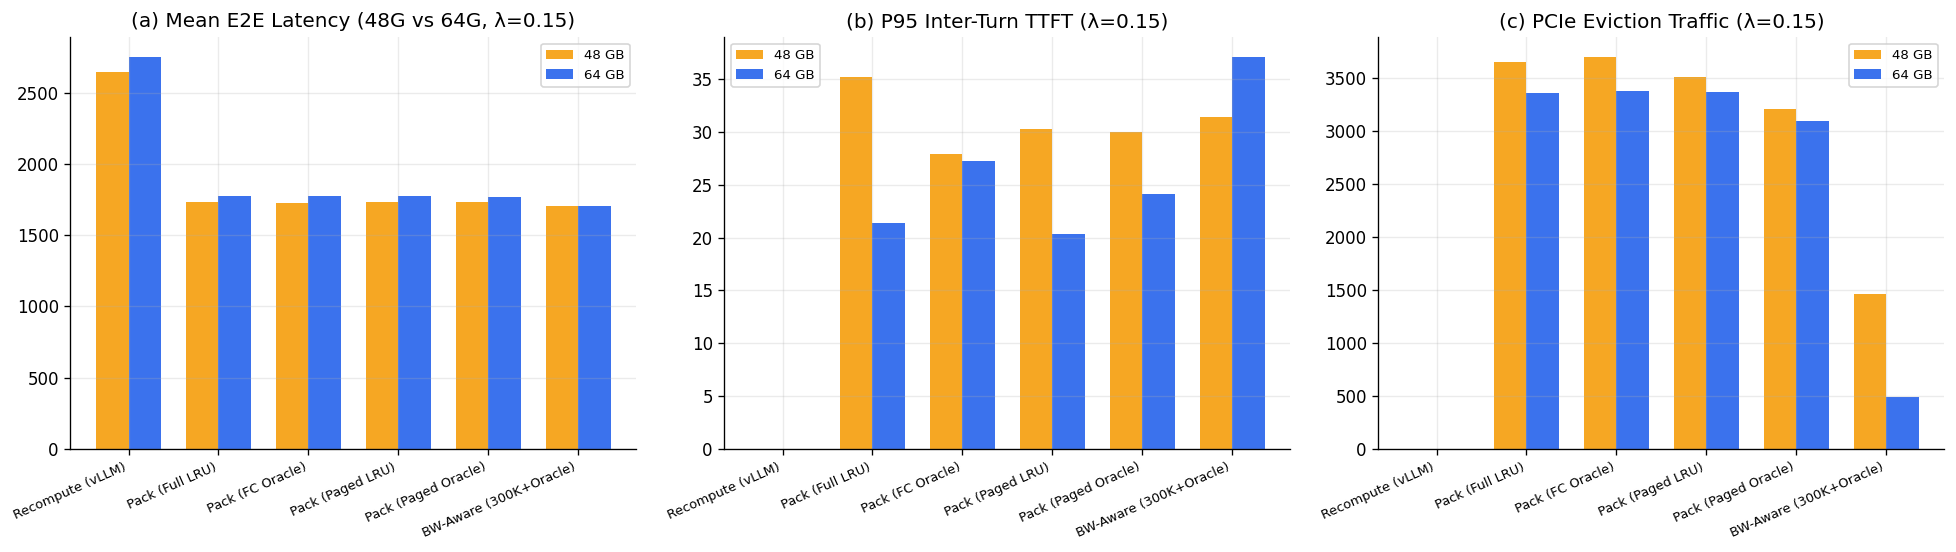

In [2]:
# Experiment 2: 6-Policy Shootout at 48 GB & 64 GB (lambda = 0.15 and 0.25)
shootout_policies = [
    ("1. Recompute (vLLM)",       "RecomputeVLLM",       {}, "#dc2626"),
    ("2. Pack (Full LRU)",        "Baseline Full LRU",   {}, "#94a3b8"),
    ("3. Pack (FC Oracle)",       "Full-Conv Oracle",    {}, "#cbd5e1"),
    ("4. Pack (Paged LRU)",       "Naive Paged LRU",     {}, "#64748b"),
    ("5. Pack (Paged Oracle)",    "Paged Oracle (JIT)",  {}, "#475569"),
    (f"6. BW-Aware ({best_r//1000}K+Oracle)", "CappedPagedOracle", {"r_cap": best_r, "sjf": False}, "#2563eb"),
]

exp2_tasks = []
for rate in [0.15, 0.25]:
    for hbm in [48.0, 64.0]:
        for lbl, bp, kw, _ in shootout_policies:
            exp2_tasks.append((f"{rate}|{hbm:.0f}G|{lbl}", bp, hbm, rate, n_req, seed, max_time, trace_path, kw))

exp2_res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, exp2_tasks):
        exp2_res[k] = s

print(f"=== Experiment 2: 6-Policy Shootout ===")
print(f"{'Rate':4s} | {'HBM':4s} | {'Policy':26s} | {'MeanE2E':9s} | {'Decode/r':8s} | {'TTFTp95':8s} | {'EvictGB':8s} | {'LastDone':9s}")
print("-" * 96)
for rate in [0.15, 0.25]:
    for hbm in [48.0, 64.0]:
        for lbl, _, _, _ in shootout_policies:
            s = exp2_res[f"{rate}|{hbm:.0f}G|{lbl}"]
            dec = s["state_seconds"]["DECODE"] / s["total_requests"]
            print(f"{rate:4.2f} | {hbm:3.0f}G | {lbl:26s} | {s['mean_e2e_s']:7.1f} s | {dec:6.1f} s | {s['ttft_p95']:6.2f} s | {s['total_evicted_gb']:6.1f} G | {s['makespan_done_s']:7.1f} s")
        print("-" * 96)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7))
xp = np.arange(len(shootout_policies))
short_p = [p[0].split(". ")[1] for p in shootout_policies]
for ax, metric, title, skip_rec in [
    (axes[0], "mean_e2e_s",       "(a) Mean E2E Latency (48G vs 64G, λ=0.15)", False),
    (axes[1], "ttft_p95",         "(b) P95 Inter-Turn TTFT (λ=0.15)", True),
    (axes[2], "total_evicted_gb", "(c) PCIe Eviction Traffic (λ=0.15)", True),
]:
    w = 0.36
    v48 = [0.0 if (skip_rec and "Recompute" in p[0]) else exp2_res[f"0.15|48G|{p[0]}"][metric] for p in shootout_policies]
    v64 = [0.0 if (skip_rec and "Recompute" in p[0]) else exp2_res[f"0.15|64G|{p[0]}"][metric] for p in shootout_policies]
    ax.bar(xp - w/2, v48, w, label="48 GB", color="#f59e0b", alpha=0.9)
    ax.bar(xp + w/2, v64, w, label="64 GB", color="#2563eb", alpha=0.9)
    ax.set_xticks(xp); ax.set_xticklabels(short_p, fontsize=7.8, rotation=24, ha="right")
    ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

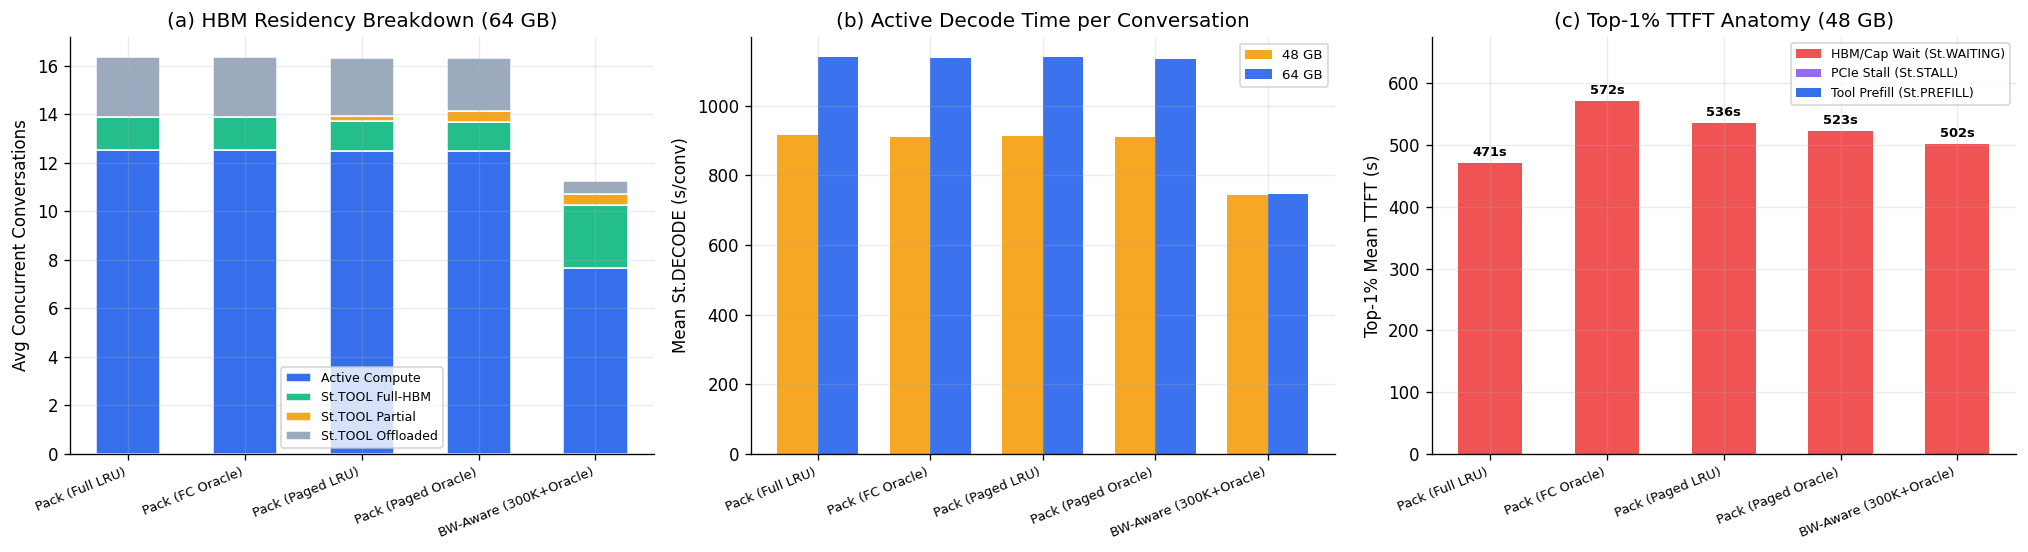

In [3]:
# Experiment 3: Mechanism Verification (Residency, Decode Speed, Top-1% TTFT Decomposition at 48 & 64 GB)
mech_policies = [p[0] for p in shootout_policies if "Recompute" not in p[0]]
xm = np.arange(len(mech_policies))
ms_lbls = [p.split(". ")[1] for p in mech_policies]

fig, axes = plt.subplots(1, 3, figsize=(17.0, 4.7))

# (a) Residency at 64 GB
act_c, full_t, part_t, off_t = [], [], [], []
for p in mech_policies:
    rs = exp2_res[f"0.15|64G|{p}"]["residency_seconds"]
    w = max(1e-9, rs["active_wall"])
    act_c.append(rs["active_compute"] / w)
    full_t.append(rs["tool_full_hbm"] / w)
    part_t.append(rs["tool_partial_hbm"] / w)
    off_t.append(rs["tool_offloaded_only"] / w)
bot = np.zeros(len(mech_policies))
for name, arr, col in [("Active Compute", act_c, "#2563eb"), ("St.TOOL Full-HBM", full_t, "#10b981"), ("St.TOOL Partial", part_t, "#f59e0b"), ("St.TOOL Offloaded", off_t, "#94a3b8")]:
    a = np.array(arr)
    axes[0].bar(xm, a, 0.55, bottom=bot, label=name, color=col, alpha=0.92, edgecolor="white")
    bot += a
axes[0].set_xticks(xm); axes[0].set_xticklabels(ms_lbls, fontsize=7.8, rotation=22, ha="right")
axes[0].set_ylabel("Avg Concurrent Conversations"); axes[0].set_title("(a) HBM Residency Breakdown (64 GB)")
axes[0].legend(fontsize=7.5)

# (b) Mean St.DECODE per Conv (48G & 64G)
w = 0.36
d48 = [exp2_res[f"0.15|48G|{p}"]["state_seconds"]["DECODE"] / exp2_res[f"0.15|48G|{p}"]["total_requests"] for p in mech_policies]
d64 = [exp2_res[f"0.15|64G|{p}"]["state_seconds"]["DECODE"] / exp2_res[f"0.15|64G|{p}"]["total_requests"] for p in mech_policies]
axes[1].bar(xm - w/2, d48, w, label="48 GB", color="#f59e0b", alpha=0.9)
axes[1].bar(xm + w/2, d64, w, label="64 GB", color="#2563eb", alpha=0.9)
axes[1].set_xticks(xm); axes[1].set_xticklabels(ms_lbls, fontsize=7.8, rotation=22, ha="right")
axes[1].set_ylabel("Mean St.DECODE (s/conv)"); axes[1].set_title("(b) Active Decode Time per Conversation")
axes[1].legend(fontsize=8)

# (c) Top-1% (p99+) TTFT Decomposition at 48 GB
pw = np.array([exp2_res[f"0.15|48G|{p}"]["ttft_decomp"]["p99_wait"] for p in mech_policies])
ps = np.array([exp2_res[f"0.15|48G|{p}"]["ttft_decomp"]["p99_stall"] for p in mech_policies])
pp = np.array([exp2_res[f"0.15|48G|{p}"]["ttft_decomp"]["p99_prefill"] for p in mech_policies])
axes[2].bar(xm, pw, 0.55, label="HBM/Cap Wait (St.WAITING)", color="#ef4444", alpha=0.92)
axes[2].bar(xm, ps, 0.55, bottom=pw, label="PCIe Stall (St.STALL)", color="#8b5cf6", alpha=0.92)
axes[2].bar(xm, pp, 0.55, bottom=pw+ps, label="Tool Prefill (St.PREFILL)", color="#2563eb", alpha=0.92)
for xi, tot in zip(xm, pw + ps + pp):
    axes[2].text(xi, tot + 6, f"{tot:.0f}s", ha="center", va="bottom", fontsize=7.8, fontweight="bold")
axes[2].set_xticks(xm); axes[2].set_xticklabels(ms_lbls, fontsize=7.8, rotation=22, ha="right")
axes[2].set_ylabel("Top-1% Mean TTFT (s)"); axes[2].set_title("(c) Top-1% TTFT Anatomy (48 GB)")
axes[2].set_ylim(0, max(pw + ps + pp) * 1.18); axes[2].legend(fontsize=7.5)
plt.tight_layout(); plt.show()

=== Experiment 4: Tight-HBM Ablation (32 -> 64 GB) ===
 32G | Pack (Full LRU)            | MeanE2E= 1736.0s | Evict=4730.5G | TTFTp95= 32.84s
 32G | Pack (Paged Oracle)        | MeanE2E= 1741.4s | Evict=3977.0G | TTFTp95= 35.60s
 32G | R_cap=300K + Paged LRU     | MeanE2E= 1734.5s | Evict=4256.6G | TTFTp95= 36.23s
 32G | R_cap=300K + Paged Oracle  | MeanE2E= 1741.4s | Evict=3977.0G | TTFTp95= 35.60s
--------------------------------------------------------------------------------
 40G | Pack (Full LRU)            | MeanE2E= 1714.9s | Evict=4073.1G | TTFTp95= 33.16s
 40G | Pack (Paged Oracle)        | MeanE2E= 1709.0s | Evict=3508.8G | TTFTp95= 27.81s
 40G | R_cap=300K + Paged LRU     | MeanE2E= 1701.3s | Evict=3051.0G | TTFTp95= 29.29s
 40G | R_cap=300K + Paged Oracle  | MeanE2E= 1701.6s | Evict=2778.0G | TTFTp95= 30.54s
--------------------------------------------------------------------------------
 48G | Pack (Full LRU)            | MeanE2E= 1734.1s | Evict=3642.7G | TTFTp95= 35.23s


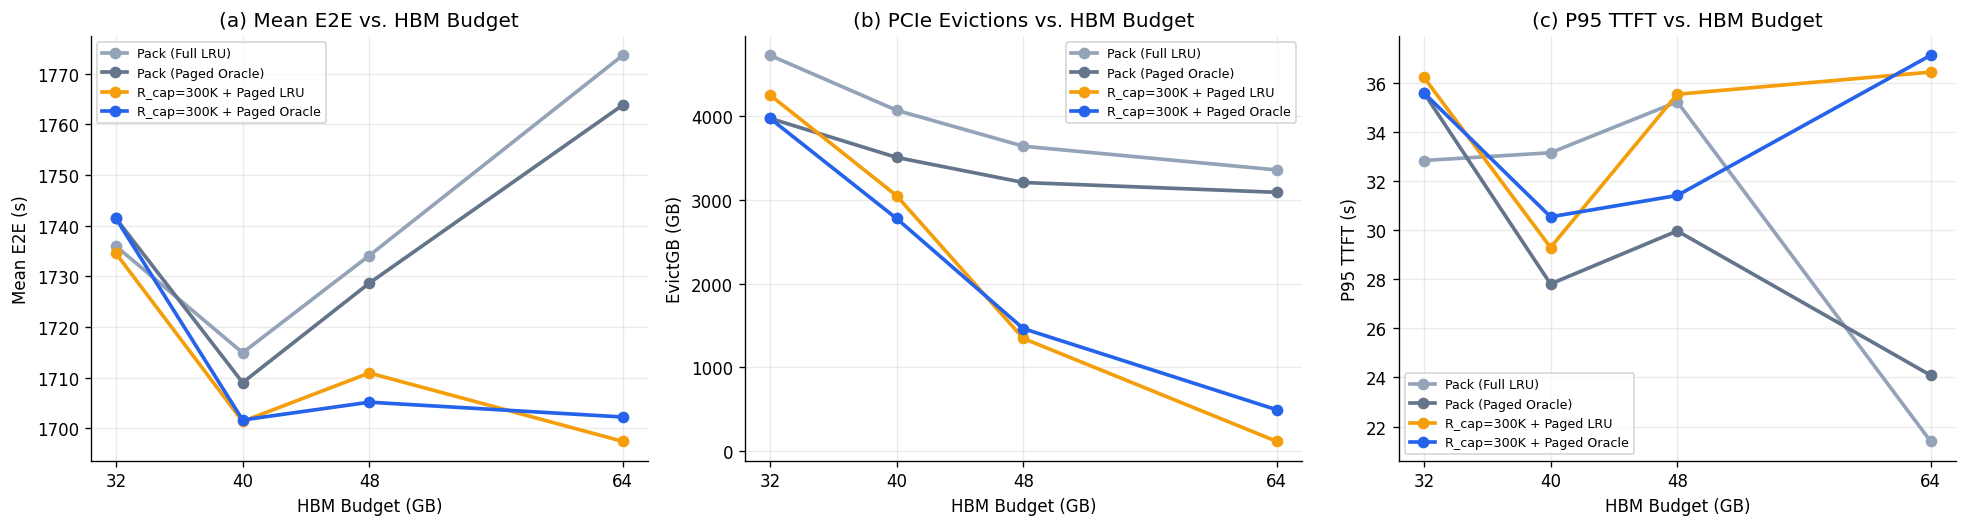

In [4]:
# Experiment 4: Tight-HBM Ablation (32, 40, 48, 64 GB) — Isolating R_bw* vs Paged Oracle
hbms4 = [32.0, 40.0, 48.0, 64.0]
abl_policies = [
    ("Pack (Full LRU)",           "Baseline Full LRU",   {},                           "#94a3b8"),
    ("Pack (Paged Oracle)",       "Paged Oracle (JIT)",  {},                           "#64748b"),
    (f"R_cap={best_r//1000}K + Paged LRU",    "CappedNaivePagedLRU", {"r_cap": best_r, "sjf": False}, "#f59e0b"),
    (f"R_cap={best_r//1000}K + Paged Oracle", "CappedPagedOracle",   {"r_cap": best_r, "sjf": False}, "#2563eb"),
]

exp4_tasks = [(f"{h:.0f}G|{lbl}", bp, h, 0.15, n_req, seed, max_time, trace_path, kw) for h in hbms4 for lbl, bp, kw, _ in abl_policies]
exp4_res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, exp4_tasks):
        exp4_res[k] = s

print("=== Experiment 4: Tight-HBM Ablation (32 -> 64 GB) ===")
for h in hbms4:
    for lbl, _, _, _ in abl_policies:
        s = exp4_res[f"{h:.0f}G|{lbl}"]
        print(f"{h:3.0f}G | {lbl:26s} | MeanE2E={s['mean_e2e_s']:7.1f}s | Evict={s['total_evicted_gb']:6.1f}G | TTFTp95={s['ttft_p95']:6.2f}s")
    print("-" * 80)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.5))
for lbl, _, _, col in abl_policies:
    axes[0].plot(hbms4, [exp4_res[f"{h:.0f}G|{lbl}"]["mean_e2e_s"] for h in hbms4], marker="o", lw=2.2, color=col, label=lbl)
    axes[1].plot(hbms4, [exp4_res[f"{h:.0f}G|{lbl}"]["total_evicted_gb"] for h in hbms4], marker="o", lw=2.2, color=col, label=lbl)
    axes[2].plot(hbms4, [exp4_res[f"{h:.0f}G|{lbl}"]["ttft_p95"] for h in hbms4], marker="o", lw=2.2, color=col, label=lbl)
axes[0].set_title("(a) Mean E2E vs. HBM Budget"); axes[0].set_ylabel("Mean E2E (s)")
axes[1].set_title("(b) PCIe Evictions vs. HBM Budget"); axes[1].set_ylabel("EvictGB (GB)")
axes[2].set_title("(c) P95 TTFT vs. HBM Budget"); axes[2].set_ylabel("P95 TTFT (s)")
for ax in axes:
    ax.set_xlabel("HBM Budget (GB)"); ax.set_xticks(hbms4); ax.legend(fontsize=7.6)
plt.tight_layout(); plt.show()

=== Experiment 5: Cross-GPU R_cap U-Curves ===
H100 PCIe (2.0 TB/s, 45G KV)   | Uncapped= 2511.8s (3313.8G) | Best R*=350K ->  2482.8s (2649.5G)
H100 SXM (3.35 TB/s, 48G KV)   | Uncapped= 1728.7s (3208.8G) | Best R*=350K ->  1702.3s (2191.8G)
H100 NVL (3.9 TB/s, 64G KV)    | Uncapped= 1590.1s (2903.8G) | Best R*=350K ->  1543.7s ( 813.6G)
H200 SXM (4.8 TB/s, 96G KV)    | Uncapped= 1368.6s ( 608.2G) | Best R*=350K ->  1346.5s (  62.5G)


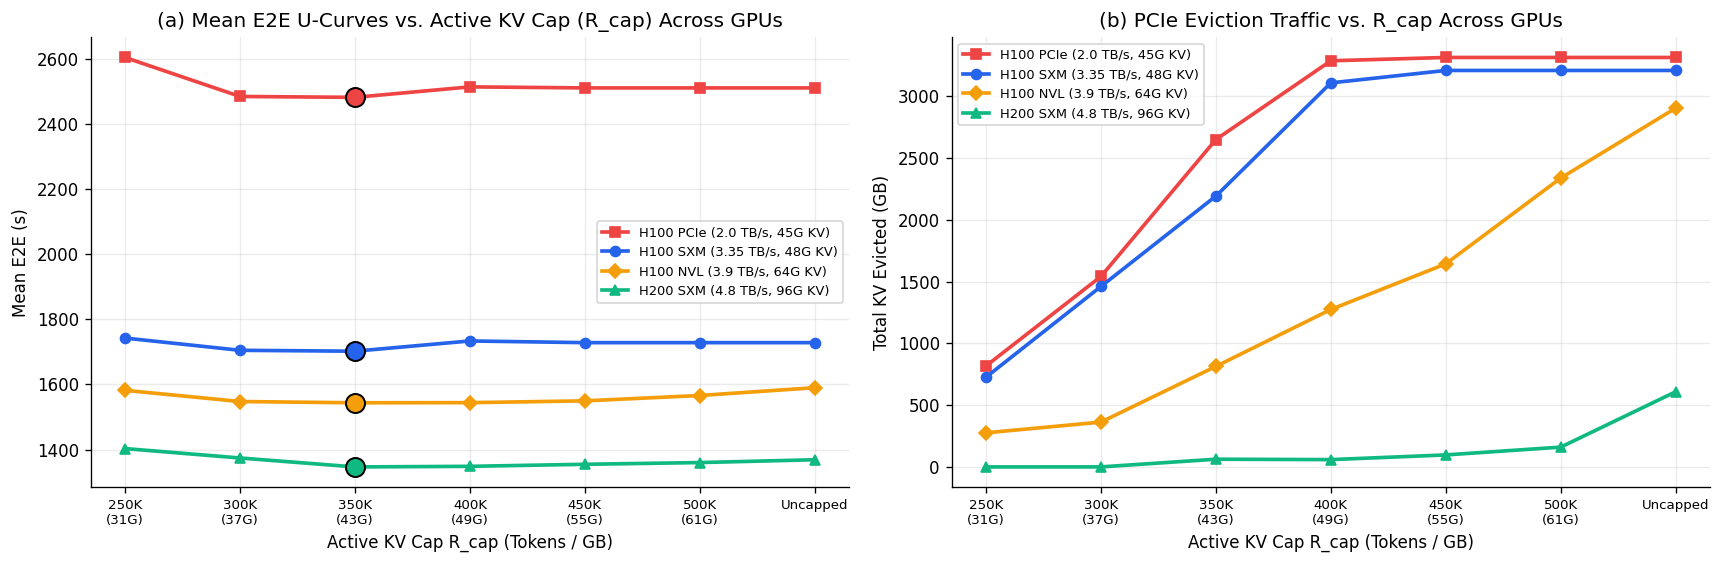

In [5]:
# Experiment 5: Cross-GPU Generalization (R_cap U-Curves Across 4 GPU Models)
gpus = [
    ("H100 PCIe (2.0 TB/s, 45G KV)", 45.0, 3.35 / 2.0, "#ef4444", "s"),
    ("H100 SXM (3.35 TB/s, 48G KV)", 48.0, 1.0,        "#2563eb", "o"),
    ("H100 NVL (3.9 TB/s, 64G KV)",  64.0, 3.35 / 3.9, "#f59e0b", "D"),
    ("H200 SXM (4.8 TB/s, 96G KV)",  96.0, 3.35 / 4.8, "#10b981", "^"),
]

exp5_tasks = []
for gname, kv_gb, rscale, _, _ in gpus:
    for r in r_caps:
        kw = {"resident_scale": rscale} if r is None else {"r_cap": r, "sjf": False, "resident_scale": rscale}
        exp5_tasks.append((f"{gname}|{r}", "CappedPagedOracle", kv_gb, 0.15, n_req, seed, max_time, trace_path, kw))

exp5_res = {}
with ProcessPoolExecutor() as ex:
    for k, s in ex.map(run_capped_sim, exp5_tasks):
        exp5_res[k] = s

print("=== Experiment 5: Cross-GPU R_cap U-Curves ===")
for gname, _, _, _, _ in gpus:
    best_g = min([r for r in r_caps if r is not None], key=lambda r: exp5_res[f"{gname}|{r}"]["mean_e2e_s"])
    u_s = exp5_res[f"{gname}|None"]
    b_s = exp5_res[f"{gname}|{best_g}"]
    print(f"{gname:30s} | Uncapped={u_s['mean_e2e_s']:7.1f}s ({u_s['total_evicted_gb']:6.1f}G) | Best R*={best_g//1000}K -> {b_s['mean_e2e_s']:7.1f}s ({b_s['total_evicted_gb']:6.1f}G)")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
for gname, _, _, col, mk in gpus:
    e2e = [exp5_res[f"{gname}|{r}"]["mean_e2e_s"] for r in r_caps]
    evg = [exp5_res[f"{gname}|{r}"]["total_evicted_gb"] for r in r_caps]
    axes[0].plot(xr, e2e, marker=mk, lw=2.2, color=col, label=gname)
    axes[1].plot(xr, evg, marker=mk, lw=2.2, color=col, label=gname)
    bi = int(np.argmin(e2e))
    axes[0].scatter([bi], [e2e[bi]], color=col, s=130, edgecolor="black", lw=1.2, zorder=6)

axes[0].set_title("(a) Mean E2E U-Curves vs. Active KV Cap (R_cap) Across GPUs")
axes[0].set_xlabel("Active KV Cap R_cap (Tokens / GB)"); axes[0].set_ylabel("Mean E2E (s)")
axes[0].set_xticks(xr); axes[0].set_xticklabels(xl, fontsize=8); axes[0].legend(fontsize=7.8)

axes[1].set_title("(b) PCIe Eviction Traffic vs. R_cap Across GPUs")
axes[1].set_xlabel("Active KV Cap R_cap (Tokens / GB)"); axes[1].set_ylabel("Total KV Evicted (GB)")
axes[1].set_xticks(xr); axes[1].set_xticklabels(xl, fontsize=8); axes[1].legend(fontsize=7.8)
plt.tight_layout(); plt.show()